Ejemplo: Clásica (Armonía y orden)
Archivo: classical.00000.wav | sr = 22050 Hz | Duración: 30.01s


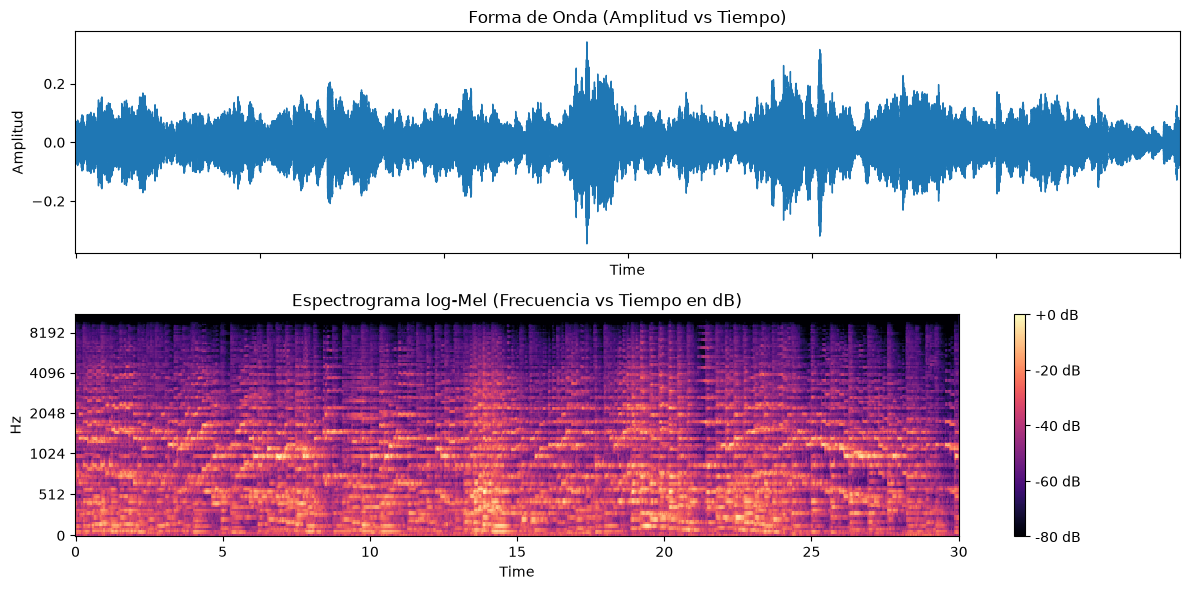

Ejemplo: Metal (Ruido y densidad)
Archivo: metal.00000.wav | sr = 22050 Hz | Duración: 30.00s


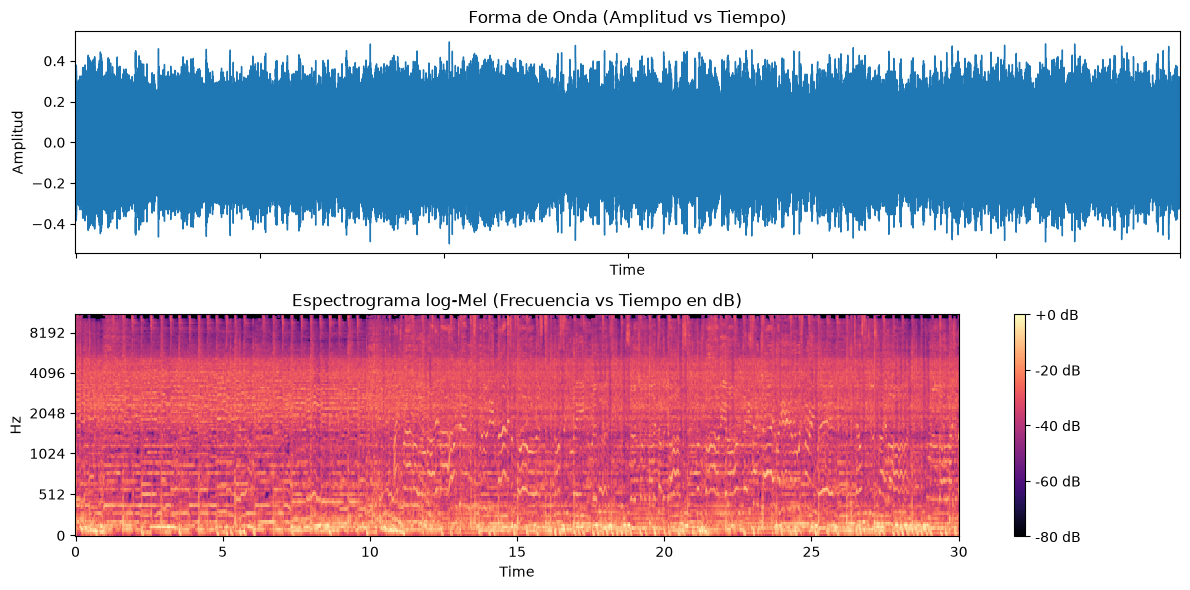

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from IPython.display import Audio, display

# 1. Definir rutas y ejemplos pedagógicos (Contraste extremo)
DATA_ROOT = Path("../data/gtzan")
EXAMPLES = {
    "Clásica (Armonía y orden)": DATA_ROOT / "classical/classical.00000.wav",
    "Metal (Ruido y densidad)": DATA_ROOT / "metal/metal.00000.wav"
}

# 2. Decisiones de análisis adaptadas a música (22050 Hz)
N_FFT = 2048       # Ventana temporal más amplia que la del llanto
HOP_LENGTH = 512   # Salto temporal
N_MELS = 128       # Mayor resolución en bandas Mel para captar instrumentos

def inspect_and_compare(title, path):
    # Cargar audio
    y, sr = librosa.load(path, sr=None) # sr=None respeta los 22050Hz originales
    
    print("=" * 60)
    print(f"Ejemplo: {title}")
    print(f"Archivo: {path.name} | sr = {sr} Hz | Duración: {len(y)/sr:.2f}s")
    print("=" * 60)
    
    # Mostrar reproductor
    display(Audio(y, rate=sr))
    
    # Calcular representaciones
    S_mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    S_logmel = librosa.power_to_db(S_mel, ref=np.max)
    
    # Configurar figura
    fig, ax = plt.subplots(nrows=2, sharex=True, figsize=(12, 6))
    
    # Gráfico 1: Forma de Onda
    librosa.display.waveshow(y, sr=sr, ax=ax[0])
    ax[0].set(title='Forma de Onda (Amplitud vs Tiempo)', ylabel='Amplitud')
    
    # Gráfico 2: Espectrograma log-Mel
    img = librosa.display.specshow(S_logmel, sr=sr, hop_length=HOP_LENGTH, x_axis='time', y_axis='mel', ax=ax[1])
    ax[1].set(title='Espectrograma log-Mel (Frecuencia vs Tiempo en dB)')
    fig.colorbar(img, ax=ax[1], format="%+2.0f dB")
    
    plt.tight_layout()
    plt.show()

# 3. Ejecutar la inspección
for title, path in EXAMPLES.items():
    if path.exists():
        inspect_and_compare(title, path)
    else:
        print(f"Archivo no encontrado: {path}")